# Занятие 1. Трансферное обучение

**Цель занятия:** научиться переносить один и тот же паттерн — *pretrained backbone → новая голова → заморозка/разморозка → LoRA* — на vision, speech и генеративные модели, а затем собрать из них мультимодальный пайплайн.

- История TL: AlexNet → VGG → ResNet → ViT → CLIP → diffusion
- ViT fine-tuning: frozen / full / LoRA
- Whisper: zero-shot WER → LoRA → WER после
- Diffusion + LoRA (DreamBooth-lite)
- Генерация аудио: AR vs diffusion vs GAN
- Мультимодальная сборка: класс восприятия + слияние
- Q&A + ДЗ

**Режимы работы.** Ноутбук сам определяет окружение:
* `FULL` — есть GPU (Colab T4/A100): реальные `google/vit-base-patch16-224`, `openai/whisper-small`, Stable Diffusion, MusicGen.
* `FAST` — CPU или слабая машина: те же API, но крошечные модели и синтетические данные. Метрики считаются на меньших объёмах.

**Про железо.** Занятие целиком демонстрируется на CPU: в `FAST` стоят маленькие модели;
`FULL` — тот же ноутбук на T4 с большими моделями.

> Ноутбук полностью исполняемый. В конце ноутбука — домашнее задание с критериями оценки.

In [2]:
import os, sys, time, math, json, random, hashlib, subprocess, warnings
from dataclasses import dataclass, field, asdict
from typing import List, Dict, Tuple, Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
try:                                   # убрать информационный шум от HF, чтобы вывод был читаемым
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error()
except Exception:
    pass

IN_COLAB = "COLAB_GPU_TOPOLOGY" in os.environ or os.path.exists("/content")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODE = os.environ.get("COURSE_MODE", "FULL" if DEVICE == "cuda" else "FAST")

if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "transformers", "datasets", "accelerate", "peft", "diffusers",
        "evaluate", "jiwer", "soundfile", "scikit-learn"])

# Воспроизводимость — обязательное требование ко всем ДЗ курса
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

@dataclass
class Cfg:
    mode: str = MODE
    device: str = DEVICE
    seed: int = SEED
    img_size: int = field(default=0)
    vit_epochs: int = field(default=0)
    vit_batch: int = field(default=0)
    whisper_steps: int = field(default=0)
    diffusion_steps: int = field(default=0)
    n_train_per_class: int = field(default=0)
    def __post_init__(self):
        fast = self.mode == "FAST"
        self.img_size = 32 if fast else 224
        self.vit_epochs = 8 if fast else 2
        self.vit_lr = 1e-3 if fast else 3e-5
        self.vit_batch = 32 if fast else 16
        self.asr_train = 10 if fast else 40     # фраз для LoRA
        self.asr_test = 4 if fast else 10       # фраз для замера WER
        self.whisper_steps = 30 if fast else 150
        self.diffusion_steps = 60 if fast else 400
        self.n_train_per_class = 60 if fast else 100

CFG = Cfg()
CLASSES = ["circle", "square", "triangle", "cross"]
COMMANDS = ["stop", "forward", "back", "left", "right", "home"]

os.makedirs("/home/user/course/artifacts", exist_ok=True)
print(f"Режим: {CFG.mode.upper()} | устройство: {DEVICE} | размер изображения: {CFG.img_size}px")

Режим: FAST | устройство: cpu | размер изображения: 32px


## Зачем это и где применяется

**Зачем.** Обучать модель с нуля под свою задачу почти никогда не нужно: предобученная сеть уже
умеет извлекать признаки, а вам остаётся адаптировать «голову» под свои классы. На занятии один
и тот же приём применяется к картинкам, речи и генерации — дальше он везде работает одинаково.

**Где применяется.** Дефектоскопия на производстве (мало данных, много видов брака); медицинские
снимки; голосовое управление роботом; генерация звуковых эффектов и подложек.

## Термины занятия (глоссарий)

| Термин | Смысл |
|---|---|
| **Backbone** | предобученная «основа» модели без последнего слоя: она уже умеет извлекать признаки |
| **Голова (head)** | новый слой поверх backbone, обученный под ваш набор классов |
| **Frozen backbone** | заморозка: обучаем только голову, веса основы не трогаем |
| **Full fine-tune** | обучаем всю сеть целиком |
| **LoRA** | вместо всех весов учим два узких множителя рядом с замороженной матрицей: <1% параметров |
| **WER** | Word Error Rate — (вставки + замены + удаления) / число слов в эталоне; 0 — идеально |
| **Мел-спектрограмма** | «картинка» звука: по X — время, по Y — частоты; стандартный вход аудиомоделей |
| **Diffusion** | генерация пошаговым удалением шума из случайного тензора |
| **AR / GAN** | генерация «следующий элемент за элементом» / генератор против дискриминатора |
| **Раннее / позднее слияние** | склеить эмбеддинги модальностей / предсказать по каждой и проголосовать |
| **Эмбеддинг** | вектор признаков, которым модель представляет вход: картинку, команду, токен |


### Архитектура занятия и выбор инструментов

```
данные ──▶ backbone (веса предобучены) ──▶ голова (новая, под ваши классы) ──▶ метрика
                       ▲
       заморозка / full / LoRA  ← единственный «рычаг», который мы меняем
```

У всех трёх модальностей одна и та же схема, поэтому и код однотипный:

| Слой | Библиотека / модель | Почему именно она |
|---|---|---|
| Vision | `transformers`, `ViTForImageClassification` | тот же API, что у BERT: готовые веса + голова под любое число классов |
| Адаптация | `peft` (LoRA) | учим <1% параметров; адаптеры хранятся отдельно от базовой модели |
| Speech | `transformers`, Whisper | мультиязычная ASR-модель вместе с процессором (мел-спектрограмма + токенизация) |
| Генерация изображений | `diffusers`: `UNet2DModel` + `DDPMScheduler` | модель предсказания шума отделена от расписания шума — их можно менять независимо |
| Генерация аудио | свои мини-модели (AR / UNet / GAN) | полноценный MusicGen не соберётся в CPU-режиме, но три подхода видно и на игрушках |
| Метрика речи | `jiwer` | стандартная реализация WER, совпадающая с той, что используют в статьях |
| Интерфейс | `abc` из стандартной библиотеки | контракт модуля зафиксирован в коде, а не в договорённостях |

Всё считается на CPU: в `FAST` стоят игрушечные модели вместо «боевых», но API и выводы те же.


## 1. История трансферного обучения в зрении

Ключевая идея: признаки, выученные на большой задаче, полезны на маленькой. Дальше меняется только то,
**что именно** мы считаем "хорошими признаками" и **как** адаптируем модель.

In [3]:
import pandas as pd
from IPython.display import display

timeline = pd.DataFrame([
    dict(год=2012, архитектура="AlexNet",      идея="CNN + GPU, ReLU, dropout",              как_переносим="заморозка conv, обучение FC"),
    dict(год=2014, архитектура="VGG / GoogLeNet", идея="глубже и однороднее",                 как_переносим="feature extraction со средних слоёв"),
    dict(год=2015, архитектура="ResNet",       идея="residual connections, очень глубокие",   как_переносим="стандарт ImageNet-backbone"),
    dict(год=2020, архитектура="ViT",          идея="трансформер на патчах, претрейн на ImageNet-21k/JFT", как_переносим="full fine-tune + LoRA"),
    dict(год=2021, архитектура="CLIP",         идея="контрастивное обучение (картинка↔текст)", как_переносим="zero-shot по текстовым промптам"),
    dict(год=2022, архитектура="Diffusion / SD", идея="денойзинг-генерация, text conditioning", как_переносим="LoRA / DreamBooth / ControlNet"),
    dict(год=2023, архитектура="Whisper / wav2vec2", идея="слабая разметка речи → robust ASR", как_переносим="LoRA на доменной лексике"),
    dict(год=2024, архитектура="LLM + adapters", идея="общий backbone для всего",              как_переносим="LoRA/QLoRA + выравнивание"),
])
display(timeline)

print("Один и тот же паттерн_transfer для всех строк таблицы:\n")
print("""  pretrained backbone  ->  (заменить/добавить голову)  ->  выбрать, что морозим  ->  метрики до/после
                                    |
                                    +-- frozen backbone   : быстро, мало данных, риск underfit
                                    +-- full fine-tune    : дорого, лучше потолок, риск catastrophic forgetting
                                    +-- LoRA / adapters   : ~0.1-2% параметров, почти как full, можно переключать адаптеры""")

,год,архитектура,идея,как_переносим
0,2012,AlexNet,"CNN + GPU, ReLU, dropout","заморозка conv, обучение FC"
1,2014,VGG / GoogLeNet,глубже и однороднее,feature extraction со средних слоёв
2,2015,ResNet,"residual connections, очень глубокие",стандарт ImageNet-backbone
3,2020,ViT,"трансформер на патчах, претрейн на ImageNet-21...",full fine-tune + LoRA
4,2021,CLIP,контрастивное обучение (картинка↔текст),zero-shot по текстовым промптам
5,2022,Diffusion / SD,"денойзинг-генерация, text conditioning",LoRA / DreamBooth / ControlNet
6,2023,Whisper / wav2vec2,слабая разметка речи → robust ASR,LoRA на доменной лексике
7,2024,LLM + adapters,общий backbone для всего,LoRA/QLoRA + выравнивание


Один и тот же паттерн_transfer для всех строк таблицы:

  pretrained backbone  ->  (заменить/добавить голову)  ->  выбрать, что морозим  ->  метрики до/после
                                    |
                                    +-- frozen backbone   : быстро, мало данных, риск underfit
                                    +-- full fine-tune    : дорого, лучше потолок, риск catastrophic forgetting
                                    +-- LoRA / adapters   : ~0.1-2% параметров, почти как full, можно переключать адаптеры


## 2. Практика: fine-tuning ViT

Сравним три стратегии на одном датасете и одном количестве шагов:
1. **Frozen backbone** — обучается только классификатор.
2. **Full fine-tune** — обучается всё.
3. **LoRA** — обучаются низкоранговые добавки в attention + голова.

Датасет: синтетика (фигуры) | 240 изображений | классы: ['circle', 'square', 'triangle', 'cross']


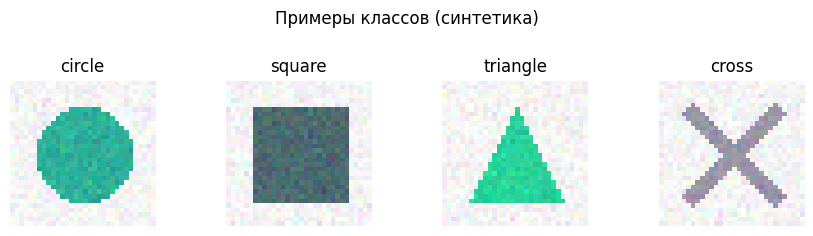

In [4]:
from PIL import Image, ImageDraw

def draw_shape(cls_name: str, size: int, rng: np.random.Generator) -> Image.Image:
    """Синтетический 'промышленный' датасет: геометрические фигуры = дефекты/объекты."""
    img = Image.new("RGB", (size, size), (245, 245, 245))
    d = ImageDraw.Draw(img)
    color = tuple(int(c) for c in rng.integers(30, 220, size=3))
    m = max(2, size // 5)
    if cls_name == "circle":
        d.ellipse([m, m, size - m, size - m], fill=color)
    elif cls_name == "square":
        d.rectangle([m, m, size - m, size - m], fill=color)
    elif cls_name == "triangle":
        d.polygon([(size // 2, m), (m, size - m), (size - m, size - m)], fill=color)
    else:  # cross
        w = max(2, size // 8)
        d.line([m, m, size - m, size - m], fill=color, width=w)
        d.line([size - m, m, m, size - m], fill=color, width=w)
    a = np.asarray(img).astype(np.float32) / 255.0
    a = np.clip(a + rng.normal(0, 0.04, a.shape).astype(np.float32), 0, 1)
    return Image.fromarray((a * 255).astype(np.uint8))

def synth_images(n_per_class: int, size: int, seed: int = 0) -> Tuple[List[Image.Image], List[int]]:
    rng = np.random.default_rng(seed)
    X, y = [], []
    for li, c in enumerate(CLASSES):
        for _ in range(n_per_class):
            X.append(draw_shape(c, size, rng)); y.append(li)
    return X, y

def load_vision_dataset():
    """FULL: реальный датасет beans (болезни листьев). FAST/нет сети: синтетические фигуры."""
    global CLASSES
    if CFG.mode == "FULL":
        try:
            from datasets import load_dataset
            ds = load_dataset("AI-Lab-Makerere/beans", split="train")
            by_class = {}
            for ex in ds:
                c = int(ex["labels"])
                if len(by_class.setdefault(c, [])) < CFG.n_train_per_class:
                    by_class[c].append(ex["image"].convert("RGB"))
                if len(by_class) >= 3 and all(len(v) >= CFG.n_train_per_class for v in by_class.values()):
                    break
            names = ds.features["labels"].names
            images, labels = [], []
            for c in sorted(by_class):
                images += by_class[c]; labels += [c] * len(by_class[c])
            CLASSES = [names[c] for c in sorted(by_class)]
            return images, labels, "beans (HF)"
        except Exception as e:
            print(f"не удалось загрузить beans ({type(e).__name__}) -> синтетика")
    return *synth_images(CFG.n_train_per_class, CFG.img_size, seed=CFG.seed), "синтетика (фигуры)"

# Данные: в FULL берём реальный набор снимков, в FAST — синтетику. Дальше код одинаковый.
X_img, y_img, DATASET_NAME = load_vision_dataset()
print(f"Датасет: {DATASET_NAME} | {len(X_img)} изображений | классы: {CLASSES}")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(CLASSES), figsize=(2.2 * len(CLASSES), 2.2))
for i, ax in enumerate(axes):
    idx = y_img.index(i)
    ax.imshow(X_img[idx]); ax.set_title(CLASSES[i]); ax.axis("off")
fig.suptitle("Примеры классов (синтетика)", y=1.05)
plt.tight_layout(); plt.show()

### 2.1 Загрузка модели

In [5]:
from transformers import ViTForImageClassification, ViTConfig, AutoImageProcessor

def build_vit(num_labels: int):
    """Возвращает (model, processor). Processor=None в FAST-режиме (там свой transform)."""
    if CFG.mode == "FAST":
        cfg = ViTConfig(hidden_size=96, num_hidden_layers=3, num_attention_heads=3,
                        intermediate_size=192, image_size=CFG.img_size, patch_size=8,
                        num_labels=num_labels, num_channels=3)
        return ViTForImageClassification(cfg), None
    name = "google/vit-base-patch16-224"
    proc = AutoImageProcessor.from_pretrained(name)
    model = ViTForImageClassification.from_pretrained(
        name, num_labels=num_labels, ignore_mismatched_sizes=True)
    return model, proc

def build_transform(processor):
    if processor is not None:
        def f(img):
            return processor(images=img, return_tensors="pt")["pixel_values"][0]
        return f
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    def f(img):
        a = np.asarray(img.resize((CFG.img_size, CFG.img_size))).astype(np.float32) / 255.0
        a = (a - mean) / std
        return torch.from_numpy(a.transpose(2, 0, 1))
    return f

class ImgDS(torch.utils.data.Dataset):
    def __init__(self, images, labels, tf):
        self.images, self.labels, self.tf = images, labels, tf
    def __len__(self): return len(self.labels)
    def __getitem__(self, i): return self.tf(self.images[i]), self.labels[i]

def split(items, labels, test_ratio=0.25):
    idx = np.random.RandomState(CFG.seed).permutation(len(labels))
    n_test = int(len(idx) * test_ratio)
    tr = [(items[i], labels[i]) for i in idx[n_test:]]
    te = [(items[i], labels[i]) for i in idx[:n_test]]
    return (list(zip(*tr)) if tr else ([], [])), (list(zip(*te)) if te else ([], []))

(x_tr, y_tr), (x_te, y_te) = split(X_img, y_img)
_, processor = build_vit(len(CLASSES))
tf = build_transform(processor)
train_dl = torch.utils.data.DataLoader(ImgDS(x_tr, y_tr, tf), batch_size=CFG.vit_batch, shuffle=True)
val_dl = torch.utils.data.DataLoader(ImgDS(x_te, y_te, tf), batch_size=CFG.vit_batch)
print(f"train: {len(x_tr)} | val: {len(x_te)}")

train: 180 | val: 60


### 2.2 Обучение и сравнение стратегий

In [7]:
!pip install --upgrade torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 28.7 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [8]:
@torch.no_grad()
def evaluate_clf(model, dl, device) -> float:
    model.eval(); correct = total = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(pixel_values=xb).logits
        correct += int((logits.argmax(-1) == yb).sum()); total += yb.size(0)
    return correct / max(total, 1)

def train_clf(model, train_dl, val_dl, epochs, lr, device, label="") -> Dict:
    params = [p for p in model.parameters() if p.requires_grad]   # учим только незамороженное
    opt = torch.optim.AdamW(params, lr=lr)
    t0 = time.time(); hist = []
    for ep in range(epochs):
        model.train(); tot, n = 0.0, 0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(pixel_values=xb, labels=yb)
            opt.zero_grad(); out.loss.backward(); opt.step()
            tot += float(out.loss) * xb.size(0); n += xb.size(0)
        acc = evaluate_clf(model, val_dl, device)
        hist.append(dict(epoch=ep + 1, loss=round(tot / max(n, 1), 4), val_acc=round(acc, 4)))
        if label: print(f"  [{label}] epoch {ep+1}/{epochs} loss={hist[-1]['loss']} val_acc={acc:.3f}")
    return dict(strategy=label, val_acc=max(h["val_acc"] for h in hist),
                final_val_acc=hist[-1]["val_acc"], time_s=round(time.time() - t0, 1),
                trainable_params=sum(p.numel() for p in params), hist=hist)

# Три стратегии отличаются только тем, у каких параметров выставлено requires_grad=True:
# это единственный «рычаг», который мы здесь меняем.
def make_strategies(num_labels):
    from peft import LoraConfig, get_peft_model
    m1, _ = build_vit(num_labels)
    for n, p in m1.named_parameters():
        p.requires_grad = ("classifier" in n)                      # frozen backbone
    m2, _ = build_vit(num_labels)                                   # full fine-tune
    m3, _ = build_vit(num_labels)
    m3 = get_peft_model(m3, LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj", "v_proj"]))
    for n, p in m3.named_parameters():                              # голова + LoRA
        p.requires_grad = (("classifier" in n) or ("lora_" in n))
    return [("frozen backbone", m1), ("full fine-tune", m2), ("LoRA", m3)]

results_vit = []
trained = {}
for name, model in make_strategies(len(CLASSES)):
    model.to(DEVICE)
    print(f"\n=== {name} ===")
    r = train_clf(model, train_dl, val_dl, epochs=CFG.vit_epochs,
                  lr=CFG.vit_lr, device=DEVICE, label=name)
    results_vit.append(r); trained[name] = model
    model.to("cpu")

df_vit = pd.DataFrame([{k: r[k] for k in ("strategy", "val_acc", "final_val_acc", "time_s", "trainable_params")}
                       for r in results_vit]).sort_values("val_acc", ascending=False)
display(df_vit)

best_name = df_vit.iloc[0]["strategy"]
best_model = trained[best_name]
print(f"\nЛучшая стратегия: {best_name} (val_acc={df_vit.iloc[0]['val_acc']:.3f})")

W1114 13:26:25.441000 842 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.



=== frozen backbone ===
  [frozen backbone] epoch 1/8 loss=1.3815 val_acc=0.517
  [frozen backbone] epoch 2/8 loss=1.349 val_acc=0.467
  [frozen backbone] epoch 3/8 loss=1.3266 val_acc=0.517
  [frozen backbone] epoch 4/8 loss=1.305 val_acc=0.633
  [frozen backbone] epoch 5/8 loss=1.2841 val_acc=0.533
  [frozen backbone] epoch 6/8 loss=1.2631 val_acc=0.617
  [frozen backbone] epoch 7/8 loss=1.2431 val_acc=0.783
  [frozen backbone] epoch 8/8 loss=1.2252 val_acc=0.767

=== full fine-tune ===
  [full fine-tune] epoch 1/8 loss=1.4894 val_acc=0.317
  [full fine-tune] epoch 2/8 loss=1.3047 val_acc=0.583
  [full fine-tune] epoch 3/8 loss=1.2079 val_acc=0.533
  [full fine-tune] epoch 4/8 loss=1.0482 val_acc=0.500
  [full fine-tune] epoch 5/8 loss=0.9777 val_acc=0.567
  [full fine-tune] epoch 6/8 loss=0.711 val_acc=0.900
  [full fine-tune] epoch 7/8 loss=0.5309 val_acc=1.000
  [full fine-tune] epoch 8/8 loss=0.3439 val_acc=1.000

=== LoRA ===
  [LoRA] epoch 1/8 loss=1.39 val_acc=0.283
  [LoRA] 

,strategy,val_acc,final_val_acc,time_s,trainable_params
1,full fine-tune,1.0000,1.0000,4.3,245188
2,LoRA,1.0000,1.0000,4.6,9604
0,frozen backbone,0.7833,0.7667,2.8,388



Лучшая стратегия: full fine-tune (val_acc=1.000)


## 3. Практика: Whisper (распознавание речи)

**Как устроен Whisper:** encoder-decoder Transformer. Энкодер принимает мел-спектрограмму
(30-секундное окно), декодер генерирует текст и заодно предсказывает язык и задачу
(транскрибация или перевод). Поэтому одна и та же модель работает на десятках языков без переобучения.

Замеряем WER (word error rate) до дообучения, затем дообучаем LoRA на доменной лексике и перезамеряем.
В `FULL`-режиме вместо синтетики можно взять реальный датасет.

In [9]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration
import jiwer

WHISPER_ID = "openai/whisper-tiny" if CFG.mode == "FAST" else "openai/whisper-small"
SR = 16000

def load_speech(n_train: int, n_test: int, max_seconds: float = 6.0, max_chars: int = 90):
    """Реальная речь из крошечного публичного датасета librispeech_asr_dummy.
    Parquet читаем напрямую (pandas + soundfile), чтобы не зависеть от torchcodec."""
    import pandas as pd, soundfile as sf, io, urllib.request
    url = ("https://huggingface.co/datasets/hf-internal-testing/librispeech_asr_dummy"
           "/resolve/main/clean/validation-00000-of-00001.parquet")
    os.makedirs("/home/user/course/artifacts/data", exist_ok=True)
    path = "/home/user/course/artifacts/data/ls_dummy.parquet"
    if not os.path.exists(path):
        print("скачиваем мини-датасет речи (~9 МБ)...")
        urllib.request.urlretrieve(url, path)
    items = []
    for _, r in pd.read_parquet(path).iterrows():
        text = str(r["text"]).lower().strip()
        if len(text) > max_chars:
            continue
        audio, sr = sf.read(io.BytesIO(r["audio"]["bytes"]))
        audio = np.asarray(audio, dtype=np.float32)
        if sr != SR:                                   # whisper ожидает 16 кГц
            audio = audio[:: max(1, sr // SR)]
        if len(audio) / SR > max_seconds:
            continue
        items.append((audio, text))
        if len(items) >= n_train + n_test:
            break
    return items[:n_train], items[n_train:n_train + n_test]

def synth_command(cmd: str, rng: np.random.Generator) -> np.ndarray:
    """Доменная команда робота: кодируется последовательностью тонов (в Whisper такого нет)."""
    base = COMMANDS.index(cmd) + 1
    pat = [base * 150, base * 190, base * 115]
    audio = []
    for f in pat:
        t = np.arange(int(SR * 0.22)) / SR
        audio.append(np.sin(2 * np.pi * f * t) * 0.4)
        audio.append(np.zeros(int(SR * 0.05)))
    a = np.concatenate(audio).astype(np.float32)
    a = a + rng.normal(0, 0.02, a.shape).astype(np.float32)
    return (a / (np.abs(a).max() + 1e-6)).astype(np.float32)

def make_audio_set(n_per_cmd: int, seed: int = 1):
    rng = np.random.default_rng(seed)
    return [(synth_command(c, rng), c) for c in COMMANDS for _ in range(n_per_cmd)]

# Речь для замера WER; при отсутствии сети — синтетические команды
try:
    speech_train, speech_test = load_speech(CFG.asr_train, CFG.asr_test)
    ASR_DATA = "librispeech_asr_dummy (реальная речь)"
except Exception as e:
    print(f"нет доступа к датасету речи ({type(e).__name__}) -> синтетические команды")
    speech_train, speech_test = make_audio_set(4, seed=1), make_audio_set(1, seed=99)
    ASR_DATA = "синтетические команды робота"

# Команды робота пригодятся в разделе 6 (мультимодальная сборка)
train_audio, test_audio = make_audio_set(3, seed=1), make_audio_set(1, seed=99)
print(f"ASR: {ASR_DATA} | train={len(speech_train)} test={len(speech_test)} | whisper: {WHISPER_ID}")

wp = WhisperProcessor.from_pretrained(WHISPER_ID)
wmodel = WhisperForConditionalGeneration.from_pretrained(WHISPER_ID).to(DEVICE)
for _attr in ("suppress_tokens", "begin_suppress_tokens", "max_length"):
    if hasattr(wmodel.generation_config, _attr):
        setattr(wmodel.generation_config, _attr, None)      # убрать дублирующие ограничения генерации

@torch.no_grad()
def transcribe(model, audio: np.ndarray, max_new_tokens: int = 48) -> str:
    # процессор сам считает мел-спектрограмму из waveform: модель ждёт именно её, а не сырой звук
    feats = wp.feature_extractor(audio, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    ids = model.generate(feats, max_new_tokens=max_new_tokens, language="en", task="transcribe")
    return wp.batch_decode(ids, skip_special_tokens=True)[0].strip().lower()

def wer_on(items, model) -> Tuple[float, List[str]]:
    # WER = (вставки + замены + удаления) / число слов в эталоне; считает jiwer
    refs = [t for _, t in items]
    # пустая гипотеза ломает выравнивание в jiwer -> подставляем служебный токен
    hyps = [(transcribe(model, a) or "<eps>") for a, _ in items]
    return float(jiwer.wer(refs, hyps)), hyps

# шаг 1: WER на замороженной модели — baseline, с которым потом сравниваем дообучение
wer_before, hyps_before = wer_on(speech_test, wmodel)
print(f"\nWER до дообучения: {wer_before:.3f}")
for (_, ref), h in zip(speech_test, hyps_before):
    print(f"   ref='{ref[:60]}'\n   hyp='{h[:60]}'")

скачиваем мини-датасет речи (~9 МБ)...
ASR: librispeech_asr_dummy (реальная речь) | train=10 test=4 | whisper: openai/whisper-tiny


preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/836k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.75k [00:00<?, ?B/s]


WER до дообучения: 0.263
   ref='i also offered to help your brother to escape but he would n'
   hyp='i also offered to help your brother to escape, but he would '
   ref='he eats and sleeps very steadily replied the new king'
   hyp='it eats and sleeps very steadily, replied the new king.'
   ref='i hope he doesn't work too hard said shaggy'
   hyp='i hope he doesn't work too hard since she got me.'
   ref='he doesn't work at all'
   hyp='he doesn't work at all.'


### 3.1 LoRA fine-tune и повторный замер WER

In [10]:
from peft import LoraConfig, get_peft_model

def train_whisper_lora(model, items, steps, lr=1e-4, device="cpu"):
    pm = get_peft_model(model, LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj", "v_proj"]))
    pm.print_trainable_parameters()
    opt = torch.optim.AdamW([p for p in pm.parameters() if p.requires_grad], lr=lr)
    pm.train(); t0 = time.time(); losses = []
    for step in range(steps):
        audio, text = items[step % len(items)]
        feats = wp.feature_extractor(audio, sampling_rate=SR, return_tensors="pt").input_features.to(device)
        labels = wp.tokenizer(text, return_tensors="pt").input_ids.to(device)
        out = pm(input_features=feats, labels=labels)
        opt.zero_grad(); out.loss.backward(); opt.step()
        losses.append(float(out.loss))
        if (step + 1) % max(1, steps // 4) == 0:
            print(f"  step {step+1}/{steps} loss={np.mean(losses[-10:]):.3f}")
    return pm, {"time_s": round(time.time() - t0, 1), "final_loss": round(float(np.mean(losses[-5:])), 3)}

wmodel_trained, wstats = train_whisper_lora(wmodel, speech_train, CFG.whisper_steps, device=DEVICE)
wer_after, hyps_after = wer_on(speech_test, wmodel_trained)
print(f"\nWER после LoRA: {wer_after:.3f} | обучение: {wstats}")
for (_, ref), h in zip(speech_test, hyps_after):
    print(f"   ref='{ref[:60]}'\n   hyp='{h[:60]}'")

df_asr = pd.DataFrame([dict(модель=f"{WHISPER_ID} zero-shot", WER=round(wer_before, 3), шагов=0),
                       dict(модель=f"{WHISPER_ID} + LoRA", WER=round(wer_after, 3), шагов=CFG.whisper_steps)])
display(df_asr)

trainable params: 147,456 || all params: 37,908,096 || trainable%: 0.3890
  step 7/30 loss=5.842
  step 14/30 loss=5.106
  step 21/30 loss=4.698
  step 28/30 loss=3.932

WER после LoRA: 0.237 | обучение: {'time_s': 70.2, 'final_loss': 4.035}
   ref='i also offered to help your brother to escape but he would n'
   hyp='i also offered to help your brother to escape, but he would '
   ref='he eats and sleeps very steadily replied the new king'
   hyp='he eats and sleeps very steadily, replied the new king.'
   ref='i hope he doesn't work too hard said shaggy'
   hyp='i hope he doesn't work too hard since she got me.'
   ref='he doesn't work at all'
   hyp='he doesn't work at all.'


,модель,WER,шагов
0,openai/whisper-tiny zero-shot,0.263,0
1,openai/whisper-tiny + LoRA,0.237,30


> **Ожидаемый результат.** WER снижается уже после нескольких десятков шагов LoRA: модель подстраивается
> под домен (лексику, запись, шум). Если WER почти не меняется — проверьте `steps`
> (в FAST-режиме их всего 30) и что разметка совпадает с тем, что реально произнесено.

## 4. Практика: diffusion + LoRA (DreamBooth-lite)

Диффузионная модель предсказывает шум $\varepsilon$ по зашумлённому сэмплу $x_t$:
$$\mathcal{L} = \mathbb{E}_{x_0, t, \varepsilon}\left[\lVert \varepsilon - \varepsilon_\theta(\sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\varepsilon,\; t)\rVert^2\right]$$

LoRA здесь — ровно тот же трансфер-паттерн, что и для ViT: морозим UNet, учим низкоранговые добавки в attention.

W1114 13:28:20.312000 842 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`


trainable params: 8,192 || all params: 710,691 || trainable%: 1.1527
  step 15/60 loss=1.0545
  step 30/60 loss=0.9964
  step 45/60 loss=0.9742
  step 60/60 loss=1.0043
Обучение UNet+LoRA: 21.8 c


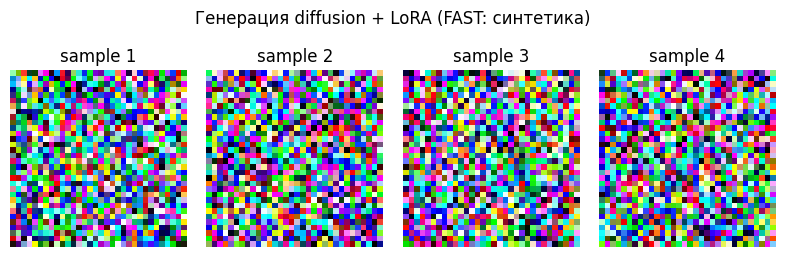

In [11]:
from diffusers import UNet2DModel, DDPMScheduler

def build_unet():
    if CFG.mode == "FAST":
        return UNet2DModel(sample_size=CFG.img_size, in_channels=3, out_channels=3,
                           layers_per_block=1, block_out_channels=(32, 64),
                           down_block_types=("DownBlock2D", "AttnDownBlock2D"),
                           up_block_types=("AttnUpBlock2D", "UpBlock2D"), norm_num_groups=8)
    return UNet2DModel.from_pretrained("google/ddpm-cifar10-32")  # компактная предобученная модель

from peft import LoraConfig as _LC, get_peft_model as _gpm
unet = build_unet()
unet_lora = _gpm(unet, _LC(r=8, lora_alpha=16, target_modules=["to_q", "to_v"]))
unet_lora.print_trainable_parameters()
unet_lora.to(DEVICE)

def images_to_tensor(imgs, size):
    mean = np.array([0.5, 0.5, 0.5], dtype=np.float32)
    std = np.array([0.5, 0.5, 0.5], dtype=np.float32)
    arr = np.stack([np.asarray(im.resize((size, size))).astype(np.float32) / 255.0 for im in imgs])
    arr = (arr - mean) / std
    return torch.from_numpy(arr.transpose(0, 3, 1, 2))

sched = DDPMScheduler(num_train_timesteps=100 if CFG.mode == "FAST" else 1000)
X_t = images_to_tensor(X_img[: 8 * len(CLASSES)], CFG.img_size)
opt = torch.optim.AdamW([p for p in unet_lora.parameters() if p.requires_grad], lr=1e-3)
t0 = time.time()
for step in range(CFG.diffusion_steps):
    b = torch.randint(0, X_t.size(0), (8,))
    x0 = X_t[b].to(DEVICE); noise = torch.randn_like(x0)
    ts = torch.randint(0, sched.config.num_train_timesteps, (x0.size(0),), device=DEVICE).long()
    noisy = sched.add_noise(x0, noise, ts)          # прямой процесс: зашумили x0
    # цель модели — предсказать добавленный шум
    opt.zero_grad()
    loss = F.mse_loss(unet_lora(noisy, ts).sample, noise)
    loss.backward(); opt.step()
    if (step + 1) % max(1, CFG.diffusion_steps // 4) == 0:
        print(f"  step {step+1}/{CFG.diffusion_steps} loss={float(loss):.4f}")
print(f"Обучение UNet+LoRA: {time.time()-t0:.1f} c")

@torch.no_grad()
def sample_unet(model, scheduler, n=4, size=None):
    size = size or CFG.img_size
    model.eval()
    x = torch.randn(n, 3, size, size, device=DEVICE)
    scheduler.set_timesteps(min(50, scheduler.config.num_train_timesteps))
    for t in scheduler.timesteps:
        t_batch = torch.full((n,), t, device=DEVICE, dtype=torch.long)
        pred = model(x, t_batch).sample               # предсказание шума на шаге t
        x = scheduler.step(pred, t, x).prev_sample    # обратный процесс: убрали долю шума
    x = (x.clamp(-1, 1) * 0.5 + 0.5).cpu().permute(0, 2, 3, 1).numpy()
    return x

samples = sample_unet(unet_lora, sched, n=4)
fig, axes = plt.subplots(1, 4, figsize=(8, 2.4))
for i, ax in enumerate(axes):
    ax.imshow(samples[i]); ax.axis("off"); ax.set_title(f"sample {i+1}")
fig.suptitle("Генерация diffusion + LoRA (FAST: синтетика)", y=1.05)
plt.tight_layout(); plt.show()

> **Для FULL-режима.** Раскомментируйте и запустите на GPU — это и есть DreamBooth-lite на 3–5 изображениях:
> Stable Diffusion + LoRA, обученная на вашем объекте/стиле.
> ```python
> from diffusers import StableDiffusionPipeline, DDPMPipeline
> sd = StableDiffusionPipeline.from_pretrained("runwayml/stable-diffusion-v1-5", torch_dtype=torch.float16).to("cuda")
> sd.unet = get_peft_model(sd.unet, LoraConfig(r=16, lora_alpha=32, target_modules=["to_q","to_v"]))
> # ... тот же цикл: add_noise -> предсказание шума -> mse -> backward
> ```

## 5. Практика: генерация аудио

| Семейство | Как устроено | Примеры | Плюсы / минусы |
|---|---|---|---|
| **Autoregressive** | предсказывает следующий токен (кодбук EnCodec) | MusicGen, Bark, Jukebox | простая цель, хорошая структура; медленный инференс, дрейф |
| **Diffusion** | денойзинг спектрограммы/латента | AudioLDM, MusicLDM | параллельная генерация, качество; много шагов |
| **GAN** | генератор против дискриминатора | MelGAN, HiFi-GAN (вокодеры) | очень быстрый инференс; нестабильное обучение, mode collapse |

Разберем авторегрессионный подход (MusicGen). Два других семейства запускают через библиотеки `diffusers`, `audiocraft` на GPU.

In [12]:
# --- 5.1 Autoregressive (MusicGen-style): предсказание следующей ноты
PITCHES, BOS = 12, 12
VOCAB = PITCHES + 1

class TinyAR(nn.Module):
    def __init__(self, vocab=VOCAB, d=32, maxlen=32):
        super().__init__()
        self.emb = nn.Embedding(vocab, d); self.pos = nn.Embedding(maxlen, d)
        layer = nn.TransformerEncoderLayer(d, nhead=4, dim_feedforward=64, dropout=0.0,
                                           batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, 1); self.head = nn.Linear(d, vocab)
    def forward(self, x):
        h = self.emb(x) + self.pos(torch.arange(x.size(1), device=x.device))[None]
        # causal-маска: токен видит только себя и предыдущие, иначе модель «подсматривает» в будущее
        mask = torch.triu(torch.ones(x.size(1), x.size(1), dtype=torch.bool, device=x.device), 1)
        return self.head(self.enc(h, mask=mask))

note_seqs = torch.tensor([[BOS] + [((k % 5 + off) % PITCHES) for off in (0, 2, 4, 2, 0, 4, 2, 0)]
                           for k in range(64)], dtype=torch.long)
ar_model = TinyAR(); opt_ar = torch.optim.Adam(ar_model.parameters(), lr=3e-3)
t0 = time.time()
for step in range(120):
    opt_ar.zero_grad()
    # таргет — последовательность со сдвигом на 1: предсказываем следующий токен
    logits = ar_model(note_seqs[:, :-1])
    loss = F.cross_entropy(logits.reshape(-1, VOCAB), note_seqs[:, 1:].reshape(-1))
    loss.backward(); opt_ar.step()
ar_time = time.time() - t0

@torch.no_grad()
def ar_generate(model, n=8, temp=0.8):
    cur = torch.tensor([[BOS]])
    for _ in range(n):
        # сэмплируем один токен и подаём обратно — отсюда линейное время генерации O(n)
        nxt = torch.multinomial(F.softmax(model(cur)[:, -1] / temp, -1), 1)
        cur = torch.cat([cur, nxt], 1)
    return cur[0, 1:].tolist()

print(f"AR: loss={float(loss):.3f}, обучение {ar_time:.1f} c, сгенерировано: {ar_generate(ar_model)}")

df_audio = pd.DataFrame([
    dict(подход="autoregressive — разобрали и запустили", модель="TinyAR (нотные токены)",
         loss=round(float(loss), 3), время_обучения_с=round(ar_time, 1), инференс="последовательно, O(n)",
         комментарий="структура мелодии воспроизводится точно"),
    dict(подход="diffusion — вариация", модель="UNet2D по mel-патчам", loss=None, время_обучения_с=None,
         инференс="N шагов денойзинга", комментарий="параллельно по времени, но нужен шедулер"),
    dict(подход="GAN — вариация", модель="MLP G/D", loss=None, время_обучения_с=None,
         инференс="один проход", комментарий="самый быстрый инференс, нестабильное обучение"),
])
display(df_audio)

AR: loss=0.202, обучение 0.9 c, сгенерировано: [4, 6, 8, 6, 4, 8, 6, 4]


,подход,модель,loss,время_обучения_с,инференс,комментарий
0,autoregressive — разобрали и запустили,TinyAR (нотные токены),0.202,0.9,"последовательно, O(n)",структура мелодии воспроизводится точно
1,diffusion — вариация,UNet2D по mel-патчам,NaN,NaN,N шагов денойзинга,"параллельно по времени, но нужен шедулер"
2,GAN — вариация,MLP G/D,NaN,NaN,один проход,"самый быстрый инференс, нестабильное обучение"


## 6. Мультимодальная сборка

Соберём обе модальности в один класс с тремя методами: `encode_image`, `transcribe_audio`, `fuse`.

In [13]:
class MultimodalPerception:
    """Модуль восприятия: картинка + голосовая команда -> (метка, уверенность).

    Раннее слияние: склеиваем эмбеддинг изображения и вектор команды, дальше один классификатор.
    Это самый простой и самый частый вариант — его и разбираем подробно."""
    def __init__(self, vision_model, img_dim: int, txt_dim: int, n_classes: int):
        self.vision = vision_model
        self.head = nn.Linear(img_dim + txt_dim, n_classes)

    def encode_image(self, image):
        xb = tf(image).unsqueeze(0).to(DEVICE)
        return image_embedding(self.vision, xb)[0].cpu()
    def transcribe_audio(self, audio):
        return transcribe(wmodel_trained, audio)
    def fuse(self, image, audio):
        # конкатенация эмбеддингов — всё раннее слияние в одной строке
        z = torch.cat([self.encode_image(image), text_to_vec(self.transcribe_audio(audio))])
        logits = self.head(z.to(DEVICE)); p = F.softmax(logits, -1)
        return CLASSES[int(p.argmax())], float(p.max())

def unwrap(model):
    """Снять PEFT-обёртку. Важно: у transformers-моделей тоже есть атрибут base_model,
    поэтому проверяем именно peft-API (get_base_model), а не hasattr(model, 'base_model')."""
    return model.get_base_model() if hasattr(model, "get_base_model") else model

@torch.no_grad()
def image_embedding(model, xb) -> torch.Tensor:
    vit = unwrap(model).vit
    out = vit(pixel_values=xb)
    return out.last_hidden_state[:, 0]          # [CLS] токен как эмбеддинг изображения

def _stable_hash(tok: str) -> int:
    """Детерминированный хеш (встроенный hash() рандомизирован между запусками — так нельзя)."""
    return int(hashlib.md5(tok.encode("utf-8")).hexdigest()[:8], 16)

def text_to_vec(text: str, dim: int = 32) -> torch.Tensor:
    """Hashing-trick: детерминированный эмбеддинг распознанной команды."""
    v = torch.zeros(dim)
    for tok in text.lower().split():
        v[_stable_hash(tok) % dim] += 1.0
    return v / (v.norm() + 1e-6)

print("Методы модуля восприятия:", [m for m in ("encode_image", "transcribe_audio", "fuse")
                                    if hasattr(MultimodalPerception, m)])

Методы модуля восприятия: ['encode_image', 'transcribe_audio', 'fuse']


### 6.1 Обучение головы раннего слияния

**Вариации слияния — списком, подробно разбираем только раннюю:**

* *позднее слияние* — отдельная голова на каждую модальность, решение голосованием;
* *взвешенное голосование* — вес модальности зависит от её уверенности;
* *слияние с пропуском* — если одной модальности нет, считаем по доступной;
* *кросс-внимание* — одна модальность «смотрит» на другую (так устроены мультимодальные LLM).

In [14]:
AUDIO_NOISE = 0.35          # доля примеров, где голосовая команда не соответствует объекту

def command_for(label: int, rng: np.random.Generator) -> str:
    """Команда робота для объекта класса label. С вероятностью AUDIO_NOISE команда случайна
    (шум канала/ошибка ASR) — иначе обе модальности тривиально разделимы и сравнивать нечего."""
    if rng.random() < AUDIO_NOISE:
        return COMMANDS[int(rng.integers(0, len(COMMANDS)))]
    return COMMANDS[label % len(COMMANDS)]

@torch.no_grad()
def build_mm_features(model, images, labels, batch=32, seed=0, noisy=True):
    zs = []
    for i in range(0, len(images), batch):
        xb = torch.stack([tf(im) for im in images[i:i + batch]]).to(DEVICE)
        zs.append(image_embedding(model, xb).cpu())
    Z = torch.cat(zs)
    rng = np.random.default_rng(seed)
    cmds = [command_for(l, rng) if noisy else COMMANDS[l % len(COMMANDS)] for l in labels]
    T = torch.stack([text_to_vec(c) for c in cmds])
    return Z, T, torch.tensor(labels)

fusion_model = trained["frozen backbone"]        # сознательно более слабый экстрактор признаков
# шаг 1: считаем эмбеддинги один раз — дальше головы учим на готовых векторах, это быстрее
Z_tr, T_tr, y_tr_mm = build_mm_features(fusion_model, x_tr, y_tr, seed=0)
Z_te, T_te, y_te_mm = build_mm_features(fusion_model, x_te, y_te, seed=1)
img_dim, txt_dim = Z_tr.size(1), T_tr.size(1)
print(f"эмбеддинги: image={img_dim}d, text={txt_dim}d, train={len(Z_tr)}, test={len(Z_te)}")

def train_head(head, Z, T, y, epochs=40, lr=1e-2):
    """Обучение головы раннего слияния: вход — конкатенация эмбеддингов двух модальностей."""
    opt = torch.optim.Adam(head.parameters(), lr=lr)
    head.to(DEVICE); Z, T, y = Z.to(DEVICE), T.to(DEVICE), y.to(DEVICE)
    for _ in range(epochs):
        opt.zero_grad()
        loss = F.cross_entropy(head(torch.cat([Z, T], -1)), y); loss.backward(); opt.step()
    with torch.no_grad():
        logits = head(torch.cat([Z, T], -1))
    return float((logits.argmax(-1) == y).float().mean())

early_head = nn.Linear(img_dim + txt_dim, len(CLASSES)).to(DEVICE)
acc_early_train = train_head(early_head, Z_tr, T_tr, y_tr_mm)

with torch.no_grad():
    acc_early = float((early_head(torch.cat([Z_te, T_te], -1).to(DEVICE)).argmax(-1)
                       == y_te_mm.to(DEVICE)).float().mean())

perception = MultimodalPerception(fusion_model, img_dim, txt_dim, len(CLASSES))
perception.head = early_head

display(pd.DataFrame([
    dict(модель="раннее слияние (concat)", val_acc=round(acc_early, 3), train_acc=round(acc_early_train, 3),
         параметров=sum(p.numel() for p in early_head.parameters())),
]))

эмбеддинги: image=96d, text=32d, train=180, test=60


,модель,val_acc,train_acc,параметров
0,раннее слияние (concat),0.933,0.978,516


### 6.2 Абляция: что даёт вторая модальность?

Прежде чем обсуждать «какое слияние лучше», всегда проверяйте главное: **а даёт ли вторая модальность
прирост вообще?**

In [15]:
def train_single(head, Z, y, epochs=40, lr=1e-2):
    """Обучение головы по одной модальности (для абляции)."""
    opt = torch.optim.Adam(head.parameters(), lr=lr)
    Z, y = Z.to(DEVICE), y.to(DEVICE)
    for _ in range(epochs):
        opt.zero_grad(); loss = F.cross_entropy(head(Z), y); loss.backward(); opt.step()
    with torch.no_grad():
        return float((head(Z).argmax(-1) == y).float().mean())

# абляция: те же головы, но вход вдвое короче — так видно, что именно даёт вторая модальность
head_img_only = nn.Linear(img_dim, len(CLASSES)).to(DEVICE)
head_txt_only = nn.Linear(txt_dim, len(CLASSES)).to(DEVICE)
acc_img_train = train_single(head_img_only, Z_tr, y_tr_mm)
acc_txt_train = train_single(head_txt_only, T_tr, y_tr_mm)

with torch.no_grad():
    acc_img = float((head_img_only(Z_te.to(DEVICE)).argmax(-1) == y_te_mm.to(DEVICE)).float().mean())
    acc_txt = float((head_txt_only(T_te.to(DEVICE)).argmax(-1) == y_te_mm.to(DEVICE)).float().mean())

display(pd.DataFrame([
    dict(конфигурация="только изображение", val_acc=round(acc_img, 3), train_acc=round(acc_img_train, 3)),
    dict(конфигурация="только аудио-команда", val_acc=round(acc_txt, 3), train_acc=round(acc_txt_train, 3)),
    dict(конфигурация="раннее слияние (concat)", val_acc=round(acc_early, 3), train_acc=round(acc_early_train, 3)),
]))
gain = acc_early - max(acc_img, acc_txt)
print(f"Прирост от слияния над лучшей одиночной модальностью: {gain:+.3f}")
print("Если прирост около нуля — вторая модальность не несёт дополнительного сигнала: "
      "это повод пересмотреть данные, а не перебирать архитектуры слияния.")

,конфигурация,val_acc,train_acc
0,только изображение,0.917,0.939
1,только аудио-команда,0.767,0.778
2,раннее слияние (concat),0.933,0.978


Прирост от слияния над лучшей одиночной модальностью: +0.017
Если прирост около нуля — вторая модальность не несёт дополнительного сигнала: это повод пересмотреть данные, а не перебирать архитектуры слияния.


### 6.3 Сквозной пайплайн: изображение + аудио → решение

Здесь вместо LLM стоит заглушка (`stub`).

In [16]:
class LLMStub:
    """Заглушка мозга до занятия 2. Интерфейс совместим с LLMBrain (decide/explain)."""
    RULES = {"stop": "остановиться", "forward": "двигаться вперёд", "back": "двигаться назад",
             "left": "повернуть влево", "right": "повернуть вправо", "home": "вернуться на базу"}
    def decide(self, context: Dict) -> str:
        obj, cmd = context.get("object"), context.get("command", "")
        action = self.RULES.get(cmd, "уточнить команду")
        return f"{action}: обнаружен объект '{obj}'"
    def explain(self, context: Dict) -> str:
        return f"контекст: {context}"

def run_pipeline(perception: MultimodalPerception, brain, image, audio) -> Dict:
    label, conf = perception.fuse(image, audio)
    cmd = perception.transcribe_audio(audio)
    ctx = {"object": label, "confidence": round(conf, 3), "command": cmd}
    return {"perception": ctx, "decision": brain.decide(ctx), "explanation": brain.explain(ctx)}

brain = LLMStub()
demo_img = x_te[0]; demo_audio, demo_ref = test_audio[0]
out = run_pipeline(perception, brain, demo_img, demo_audio)
print(f"ref='{demo_ref}' -> {out['perception']} -> решение: {out['decision']}")

ref='stop' -> {'object': 'circle', 'confidence': 0.655, 'command': '(upbeat music)'} -> решение: уточнить команду: обнаружен объект 'circle'


In [17]:
# шаг 3: сохраняем метрики в JSON — занятия 2 и 3 подхватывают этот файл вместо повторного обучения
artifacts = {
    "mode": CFG.mode, "device": DEVICE,
    "vit_strategies": [{k: v for k, v in r.items() if k != "hist"} for r in results_vit],
    "best_vision_strategy": best_name,
    "asr": {"model": WHISPER_ID, "wer_before": wer_before, "wer_after": wer_after, "steps": CFG.whisper_steps},
    "fusion": {"early_val_acc": acc_early},
    "audio_generation": df_audio.to_dict("records"),
}
with open("/home/user/course/artifacts/hw1_metrics.json", "w") as f:
    json.dump(artifacts, f, indent=2, ensure_ascii=False)
print("Сохранено: /home/user/course/artifacts/hw1_metrics.json")
print(json.dumps(artifacts["asr"], ensure_ascii=False))

Сохранено: /home/user/course/artifacts/hw1_metrics.json
{"model": "openai/whisper-tiny", "wer_before": 0.2631578947368421, "wer_after": 0.23684210526315788, "steps": 30}


## 7. Упражнения для самостоятельной работы (в ноутбуке)

1. Поменяйте `r` в LoRA (2 / 8 / 32) и постройте график `val_acc` от числа обучаемых параметров.
2. Добавьте в сравнение четвёртую стратегию: заморозить только первые N слоёв ViT.
3. Сделайте `text_to_vec` обучаемым (небольшой `nn.Embedding` по словарю команд) и измерьте прирост.
4. Реализуйте позднее слияние (отдельные головы + голосование) и сравните с ранним на тех же данных.
5. Замените `LLMStub` на любую модель с HF (`Qwen2.5-0.5B-Instruct`) и сравните качество решений.

---
# Домашнее задание 1. Мультимодальное трансферное обучение

**Цель:** собрать слой восприятия будущего проекта — модуль, который превращает
картинку и голосовую команду в одно решение, с измеренными метриками.

### Что сделать

1. **Выбрать домен.** Например: классификация дефектов на производстве; распознавание команд робота по голосу + жесту;
   медицинские снимки + заключение. Домен должен быть тем же, что в финальном проекте.
2. **Vision-модуль.** Fine-tune ViT на своём датасете (≥30 изображений, ≥3 классов).
   Сравнить **две** стратегии: frozen backbone и LoRA (full fine-tune — по желанию).
   Таблица: accuracy, время обучения, число обучаемых параметров.
3. **Audio-модуль.** Whisper для распознавания ключевых команд (на CPU — `openai/whisper-tiny`).
   Замерить WER на своём наборе (≥10 записей) до и после дообучения.
4. **Мультимодальная интеграция.** Оформить модуль восприятия классом с методами
   `encode_image`, `transcribe_audio`, `fuse` — раннее слияние (конкатенация эмбеддингов,
   как в ноутбуке). Сравнить точность с одной модальностью на отложенной выборке.
5. **Отчёт** (Markdown, 1 страница): таблица метрик, 2–3 вывода со ссылкой на числа, ссылка на Colab.

### Формат сдачи

* `hw1_<группа>.ipynb` (исполненный, с выводами ячеек) + `hw1_report.md`;
* все метрики — числами, каждое утверждение в выводах сопровождается ссылкой на таблицу/запуск.

### Технические условия

* GPU не требуется: всё считается на CPU или на бесплатном T4 в Colab.
  На CPU берите маленькие модели (`vit-tiny` / `vit-small`, `whisper-tiny`) и 1–2 эпохи:
  для сравнения стратегий этого достаточно, важна разница между ними, а не абсолютная точность.

### Критерии оценки (максимум 10 баллов)

| Критерий | Баллы | Что проверяется |
|---|---|---|
| Воспроизводимость | 1 | Задан seed, ноутбук исполняется от начала до конца, версии библиотек зафиксированы |
| Vision: стратегии TL | 3 | Реально обучены frozen и LoRA (full — по желанию); таблица accuracy, время, trainable params |
| Audio: WER до/после | 2 | ≥10 записей, WER посчитан `jiwer`, указано число шагов дообучения |
| Модуль восприятия и слияние | 3 | Класс с методами `encode_image`/`transcribe_audio`/`fuse`; слияние сравнено с одной модальностью |
| Отчёт | 1 | Таблица метрик, 2–3 вывода, каждое утверждение подкреплено числом |
